# PhilGEPS Dataset – Consolidation and Initial Distribution Analysis

This notebook:
1. Loads every `.csv` file in `philgeps-ml-project/data/raw/` into one Pandas DataFrame using a `for` loop.
2. Lists all data fields, their inferred data types, missing values, and unique-value counts.
3. Creates a distribution chart for every field:
   - Numeric measures: histograms.
   - Date-like fields: monthly frequency charts (when parsing is successful).
   - Categorical/text fields: top 20 categories, with remaining categories grouped as `Other`.
   - Numeric identifiers/codes: treated as categorical rather than continuous measurements.

## Expected folder structure

```text
philgeps-ml-project/
└── data/
    └── raw/
        ├── 2023_(APR-JUN).csv
        ├── 2023_(JAN-MAR).csv
        ├── ...
        └── DATASETS_MPHILGEPS_2026_JULY-SEPT.csv
```

**Important:** Run this notebook from the repository root (`philgeps-ml-project/`). The repository uses Git LFS. Run `git lfs install` and `git lfs pull` in a terminal from the repository root before running the notebook. The loading cell checks for LFS pointer files and stops with an explanation if the actual CSV data are not present.

## 1. Import libraries and set the data folder

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import warnings

warnings.filterwarnings("ignore")

# Run this notebook from the repository root:
# philgeps-ml-project/
DATA_FOLDER = Path("data") / "raw"

# If your notebook is stored somewhere else, replace the line above
# with the correct path, for example:
# DATA_FOLDER = Path("/path/to/philgeps-ml-project/data/raw")

print("Data folder:", DATA_FOLDER.resolve())
print("Folder exists:", DATA_FOLDER.exists())

Data folder: /Users/johnlagac/Documents/AIM/[TERM 3]/AID 504/MLProj_Github/data/raw
Folder exists: True


## 2. Load all CSV files into one DataFrame using a for loop
The code reads every CSV file in the folder, adds a source-file column for traceability, and combines the files with `pd.concat()`.

**If a CSV raises a `ParserError`:** do not use `on_bad_lines='skip'` as a first fix, because that can silently remove procurement records. Inspect the file's first lines and delimiter first. A safe diagnostic cell can print every line in a small problematic file, or the first 30 lines for a very large file.

In [2]:
import subprocess

csv_files = sorted(DATA_FOLDER.glob("*.csv"))

print(f"CSV files found: {len(csv_files)}")
for file in csv_files:
    print(file.name)

if not csv_files:
    raise FileNotFoundError(
        f"No CSV files found in {DATA_FOLDER.resolve()}. "
        "Check the folder path."
    )

# Git LFS pointer files are tiny text files, not the actual CSV datasets.
# Detect them before trying to concatenate the files.
lfs_pointer_files = []

for file in csv_files:
    with open(file, "r", encoding="utf-8", errors="ignore") as f:
        first_line = f.readline().strip()

    if first_line.startswith("version https://git-lfs.github.com/spec/"):
        lfs_pointer_files.append(file)

if lfs_pointer_files:
    print("\nGit LFS pointer files detected:")
    for file in lfs_pointer_files:
        print(" -", file.name)

    print("""
These are Git LFS pointer files, not the actual CSV datasets.

From a terminal, run the following commands from the repository root:

    git lfs install
    git lfs pull

Then restart the notebook kernel and run this cell again.
""")
    raise RuntimeError(
        "Actual CSV contents have not been downloaded. "
        "Run 'git lfs pull' from the repository root first."
    )

dataframes = []

for file in csv_files:
    print(f"Loading: {file.name}")

    temp_df = pd.read_csv(file, low_memory=False)

    # Preserve the source filename for traceability
    temp_df["source_file"] = file.name

    dataframes.append(temp_df)

# Combine all quarterly datasets.
df = pd.concat(dataframes, ignore_index=True, sort=False)

print("\nCombined dataset loaded successfully.")
print("Rows:", f"{len(df):,}")
print("Columns:", len(df.columns))
print("\nColumn names:")
for column in df.columns:
    print("-", column)

CSV files found: 4
2023_(APR-JUN).csv
2023_(JAN-MAR).csv
2023_(JUL-SEPT).csv
2023_(OCT-DEC).csv
Loading: 2023_(APR-JUN).csv
Loading: 2023_(JAN-MAR).csv
Loading: 2023_(JUL-SEPT).csv
Loading: 2023_(OCT-DEC).csv

Combined dataset loaded successfully.
Rows: 1,743,544
Columns: 47

Column names:
- Procuring Entity (PE)
- Region
- Province
- City/Municipality
- Government Branch
- PE Organization Type
- PE Organization Type (Grouped)
- Bid Reference No.
- Notice Title
- Classification
- Procurement Mode
- Business Category
- Funding Source
- Funding Instrument
- Trade Agreement
- Approved Budget of the Contract
- Published Date
- Closing Date
- Area of Delivery
- Contract Duration
- Calendar Type
- Line Item No
- Item Name
- Item Description
- Quantity
- UOM
- Item Budget
- Bid Notice Status
- Award Reference No.
- Award Title
- UNSPSC Code
- UNSPSC Description
- Published Date(Award)
- Award Date
- Contract Amount
- Award Notice Status
- Notice to Proceed Date
- Contract Effectivity Date
- C

## 3. Basic dataset overview

In [3]:
from IPython.display import display

# Show all rows and columns in the notebook output.
# WARNING: This can create a very large output for a dataset with tens of thousands of rows.
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

print("Dataset shape:", df.shape)
print("\nAll column names:")
for number, column in enumerate(df.columns, start=1):
    print(f"{number}. {column}")

# Display the complete DataFrame (all rows).
# If the output is too large for Jupyter, use display(df.head(20)) instead.
# display(df)

print("\nMemory usage (MB):",
      round(df.memory_usage(deep=True).sum() / (1024**2), 2))

Dataset shape: (1743544, 47)

All column names:
1. Procuring Entity (PE)
2. Region
3. Province
4. City/Municipality
5. Government Branch
6. PE Organization Type
7. PE Organization Type (Grouped)
8. Bid Reference No.
9. Notice Title
10. Classification
11. Procurement Mode
12. Business Category
13. Funding Source
14. Funding Instrument
15. Trade Agreement
16. Approved Budget of the Contract
17. Published Date
18. Closing Date
19. Area of Delivery
20. Contract Duration
21. Calendar Type
22. Line Item No
23. Item Name
24. Item Description
25. Quantity
26. UOM
27. Item Budget
28. Bid Notice Status
29. Award Reference No.
30. Award Title
31. UNSPSC Code
32. UNSPSC Description
33. Published Date(Award)
34. Award Date
35. Contract Amount
36. Award Notice Status
37. Notice to Proceed Date
38. Contract Effectivity Date
39. Contract End Date
40. Awardee Organization Name
41. Country of Awardee
42. Region of Awardee
43. Province of Awardee
44. City/Municipality of Awardee
45. Awardee Size
46. Awar

## 4. List all data fields

The table below shows each field's stored Pandas type, number of missing values, missing percentage, and number of distinct non-missing values.

**The summary is sorted by `Unique Values` in ascending order**, so fields with the fewest distinct values appear first. This makes low-cardinality fields easier to identify as potential categorical features and visualization candidates.

In [4]:
target_feature = "Bid Notice Status"

target_summary = pd.DataFrame({
    "Data Field": [target_feature],
    "Stored Data Type": [str(df[target_feature].dtype)],
    "Missing Values": [df[target_feature].isna().sum()],
    "Missing (%)": [df[target_feature].isna().mean() * 100],
    "Unique Values": [df[target_feature].nunique(dropna=True)]
})

target_summary["Missing (%)"] = target_summary["Missing (%)"].round(2)

display(target_summary)

,Data Field,Stored Data Type,Missing Values,Missing (%),Unique Values
0,Bid Notice Status,str,0,0.0,6


In [5]:
other_features = df.drop(columns=["Bid Notice Status"])

field_summary = pd.DataFrame({
    "Data Field": other_features.columns,
    "Stored Data Type": [str(other_features[col].dtype) for col in other_features.columns],
    "Missing Values": [other_features[col].isna().sum() for col in other_features.columns],
    "Missing (%)": [other_features[col].isna().mean() * 100 for col in other_features.columns],
    "Unique Values": [other_features[col].nunique(dropna=True) for col in other_features.columns]
})

field_summary["Missing (%)"] = field_summary["Missing (%)"].round(2)
field_summary = field_summary.sort_values("Unique Values", ascending=True).reset_index(drop=True)

display(field_summary)
print(f"Total other features: {len(other_features.columns)}")

,Data Field,Stored Data Type,Missing Values,Missing (%),Unique Values
0,Award Notice Status,str,871186,49.97,3
1,Calendar Type,str,38323,2.20,3
2,Government Branch,str,0,0.00,3
3,Classification,str,0,0.00,4
4,Awardee Size,str,912250,52.32,4
5,PE Organization Type (Grouped),str,0,0.00,4
6,source_file,str,0,0.00,4
7,Funding Source,str,0,0.00,5
8,Funding Instrument,str,0,0.00,6
9,Trade Agreement,str,0,0.00,7


Total other features: 46


## 6. Individual distribution charts – one cell per field

Only fields with **fewer than 100 unique non-missing values** are included in this visualization section. Fields with 100 or more unique values have been removed from the notebook, including their chart headings and code cells.

Each remaining field has its own executable code cell. Categorical fields are shown as bar charts; numerical fields as histograms; and date fields as monthly frequency charts. Identifier/code fields are treated as categories rather than continuous measurements.

### Target feature distributions – start here
These are the two outcome/status fields central to the analysis. Review their distributions first before examining the other predictors.

### Distribution: `Bid Notice Status` (target feature)

This target feature is shown first, separately from the other fields.

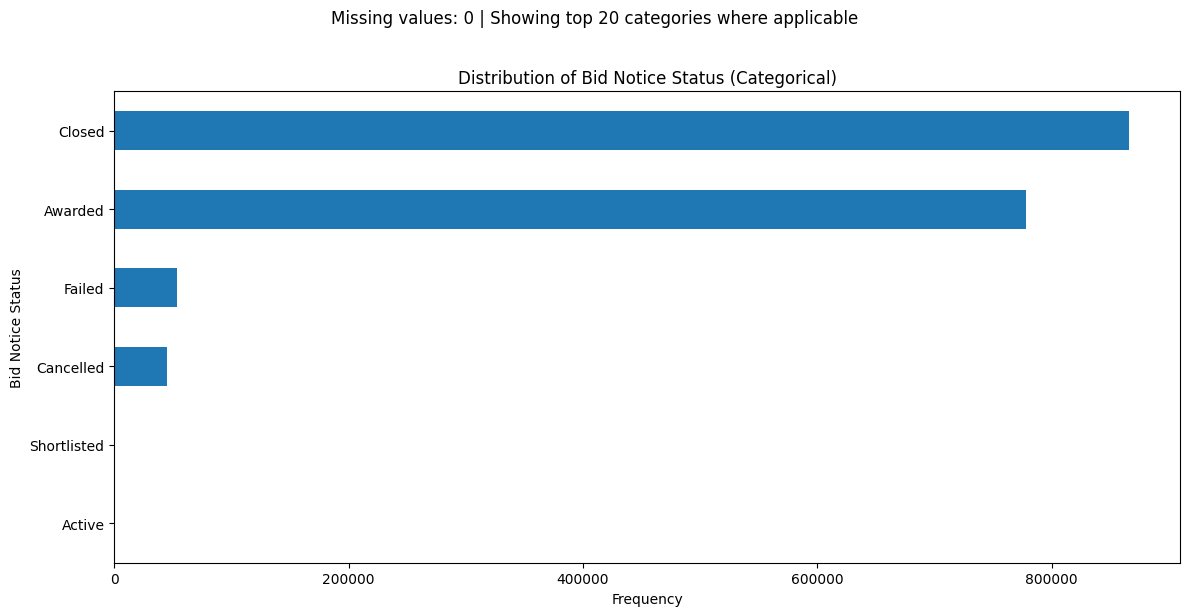

,Value,Count,Percentage (%)
0,Closed,866263,49.68
1,Awarded,778378,44.64
2,Failed,53807,3.09
3,Cancelled,44780,2.57
4,Shortlisted,296,0.02
5,Active,20,0.0


In [6]:
plot_field = 'Bid Notice Status'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)



### Other data field distributions

The existing visualization cells below are arranged in ascending order of unique values, using the counts from the supplied field summary. Only fields with **fewer than 100 unique values** are included. Each chart is preceded by a frequency table showing the count and percentage for every value.

### Distribution: `Award Notice Status` — 3 unique values

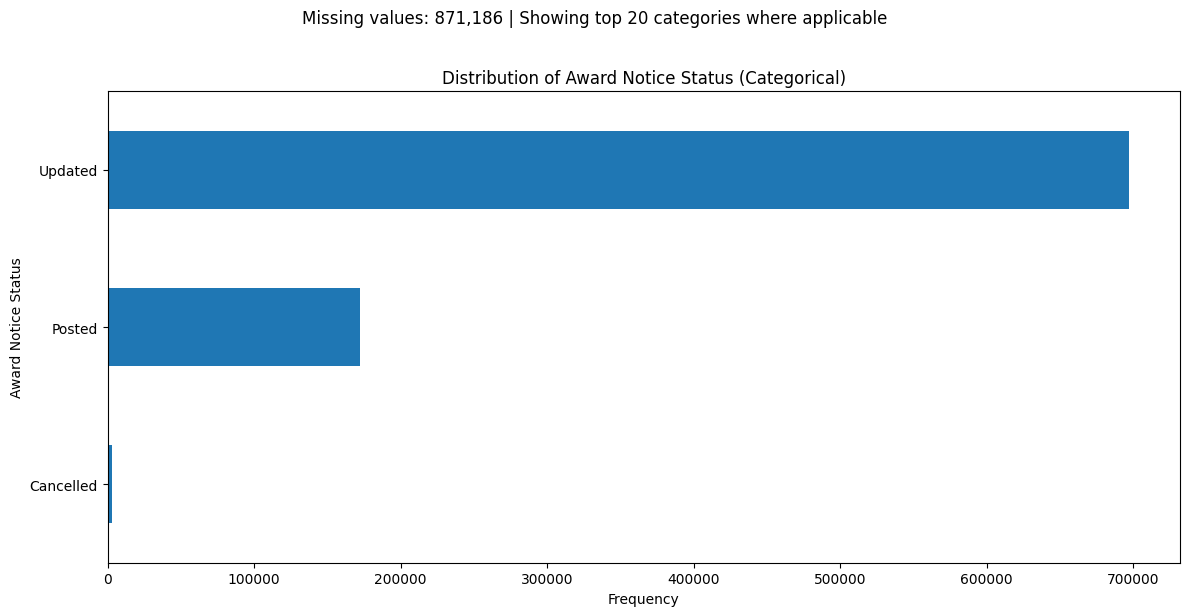

,Value,Count,Percentage (%)
0,(Missing),871186,49.97
1,Updated,697061,39.98
2,Posted,172112,9.87
3,Cancelled,3185,0.18


In [7]:
plot_field = 'Award Notice Status'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)



### Distribution: `Government Branch` — 3 unique values

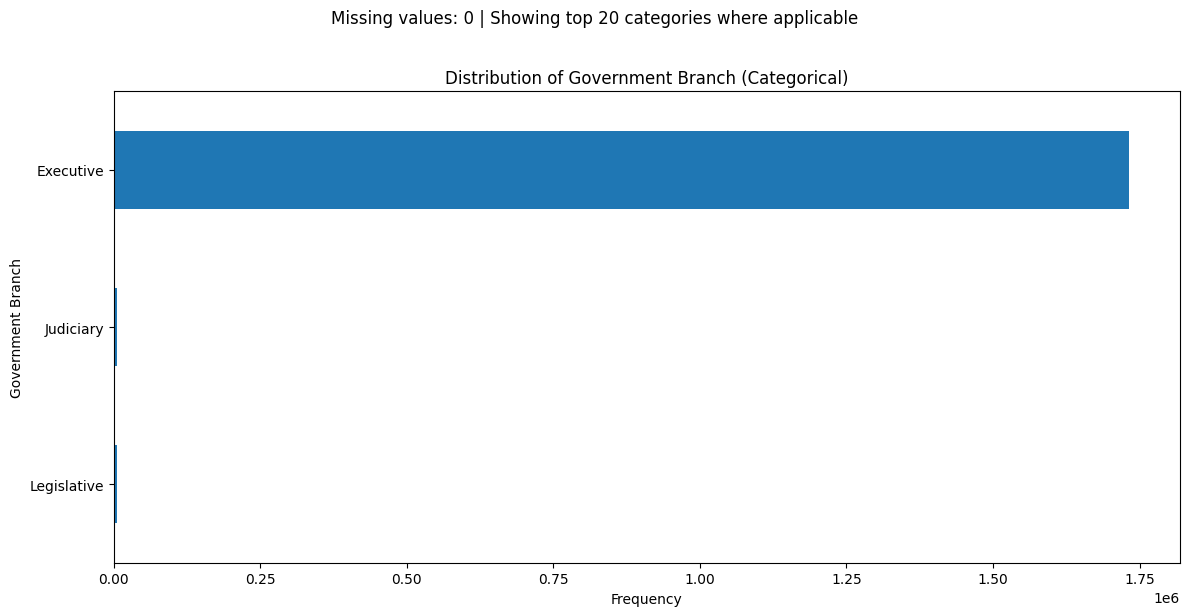

,Value,Count,Percentage (%)
0,Executive,1732330,99.36
1,Judiciary,6003,0.34
2,Legislative,5211,0.3


In [8]:
plot_field = 'Government Branch'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)



### Distribution: `Awardee Size` — 4 unique values

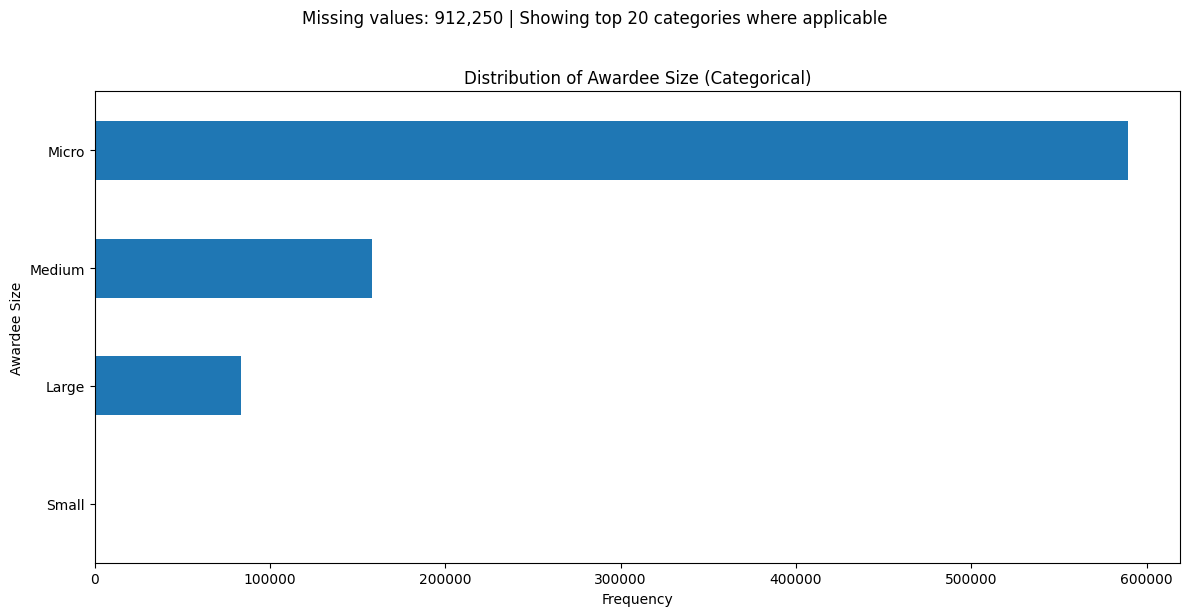

,Value,Count,Percentage (%)
0,(Missing),912250,52.32
1,Micro,589627,33.82
2,Medium,158221,9.07
3,Large,83398,4.78
4,Small,48,0.0


In [9]:
plot_field = 'Awardee Size'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)



### Distribution: `Classification` — 4 unique values

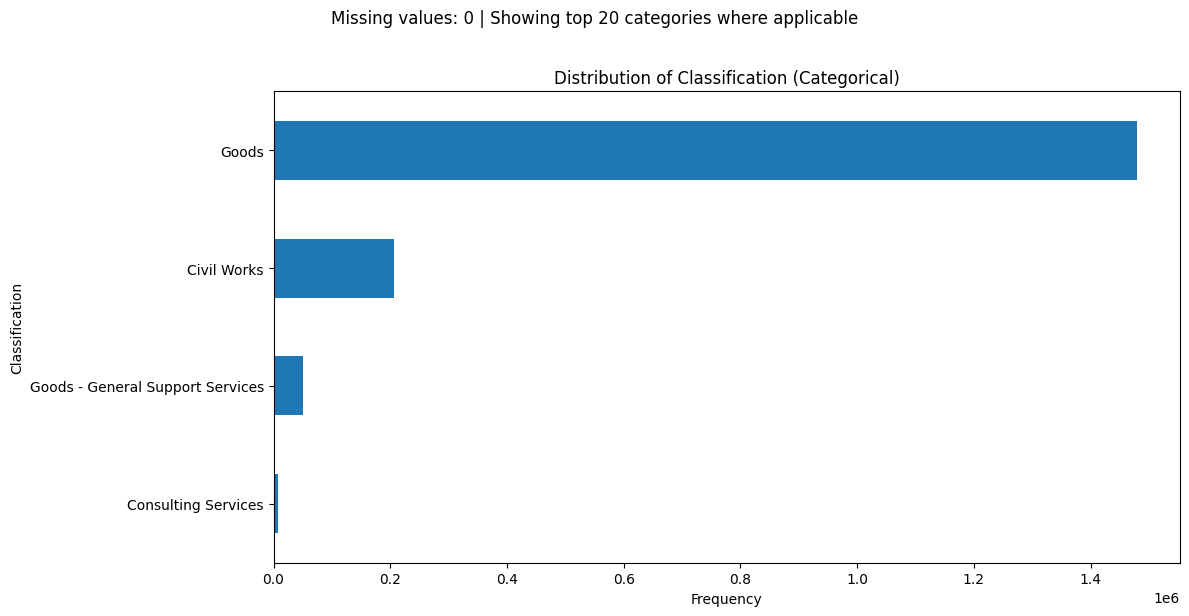

,Value,Count,Percentage (%)
0,Goods,1479202,84.84
1,Civil Works,206241,11.83
2,Goods - General Support Services,51120,2.93
3,Consulting Services,6981,0.4


In [10]:
plot_field = 'Classification'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)



### Distribution: `PE Organization Type (Grouped)` — 4 unique values

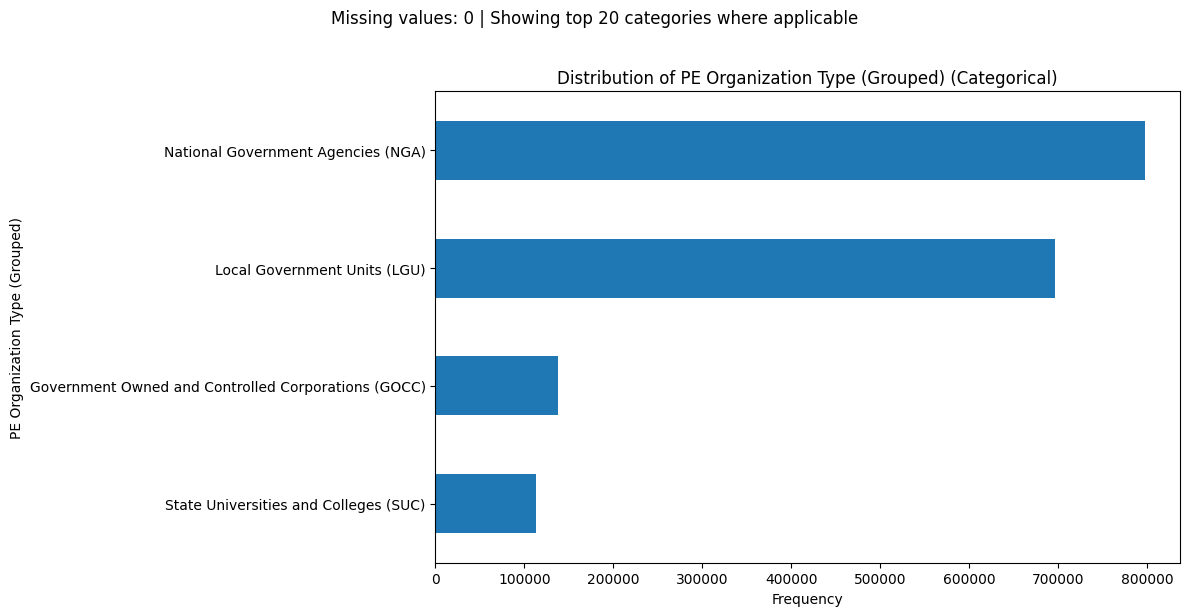

,Value,Count,Percentage (%)
0,National Government Agencies (NGA),796848,45.7
1,Local Government Units (LGU),696264,39.93
2,Government Owned and Controlled Corporations (GOCC),137434,7.88
3,State Universities and Colleges (SUC),112998,6.48


In [11]:
plot_field = 'PE Organization Type (Grouped)'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)



### Distribution: `source_file` — 4 unique values

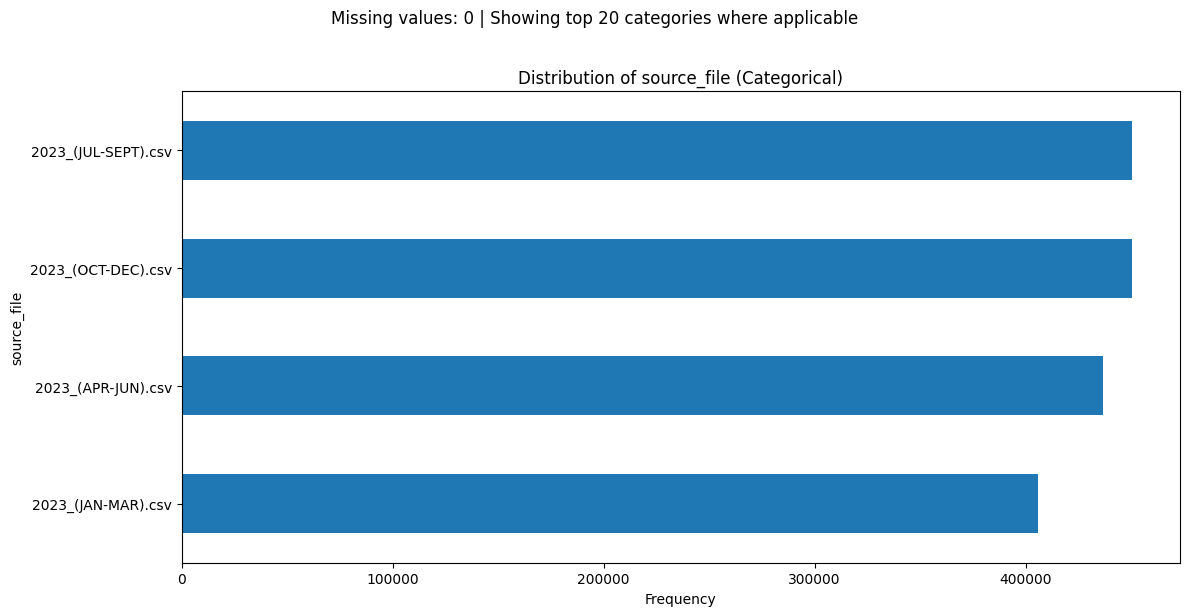

,Value,Count,Percentage (%)
0,2023_(JUL-SEPT).csv,450701,25.85
1,2023_(OCT-DEC).csv,450311,25.83
2,2023_(APR-JUN).csv,436736,25.05
3,2023_(JAN-MAR).csv,405796,23.27


In [12]:
plot_field = 'source_file'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)



### Distribution: `Funding Source` — 5 unique values

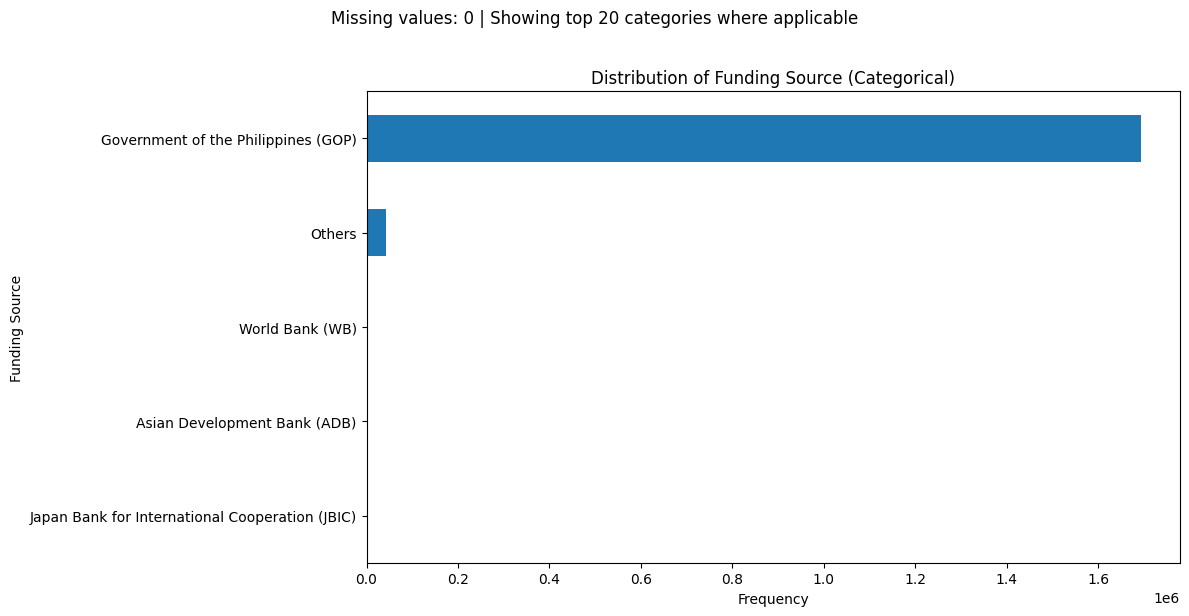

,Value,Count,Percentage (%)
0,Government of the Philippines (GOP),1694355,97.18
1,Others,41526,2.38
2,World Bank (WB),4101,0.24
3,Asian Development Bank (ADB),3266,0.19
4,Japan Bank for International Cooperation (JBIC),296,0.02


In [13]:
plot_field = 'Funding Source'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)



### Distribution: `PE Organization Type` — 14 unique values

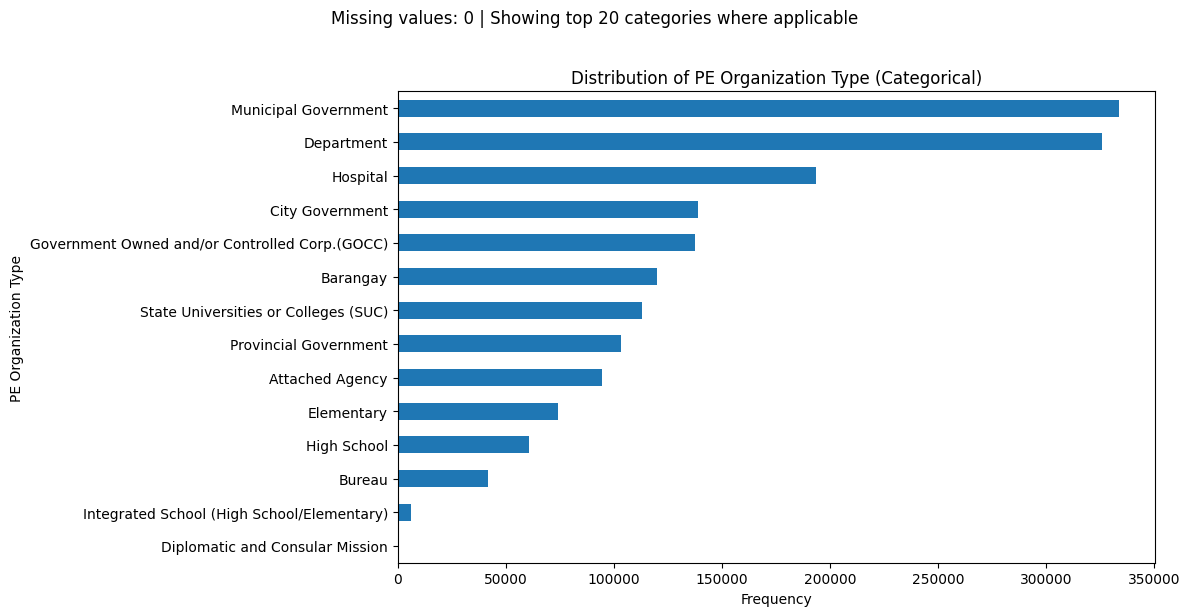

,Value,Count,Percentage (%)
0,Municipal Government,333711,19.14
1,Department,325956,18.7
2,Hospital,193731,11.11
3,City Government,138784,7.96
4,Government Owned and/or Controlled Corp.(GOCC),137434,7.88
5,Barangay,120214,6.89
6,State Universities or Colleges (SUC),112998,6.48
7,Provincial Government,103555,5.94
8,Attached Agency,94588,5.43
9,Elementary,74035,4.25


In [14]:
plot_field = 'PE Organization Type'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)



### Distribution: `Region` — 18 unique values

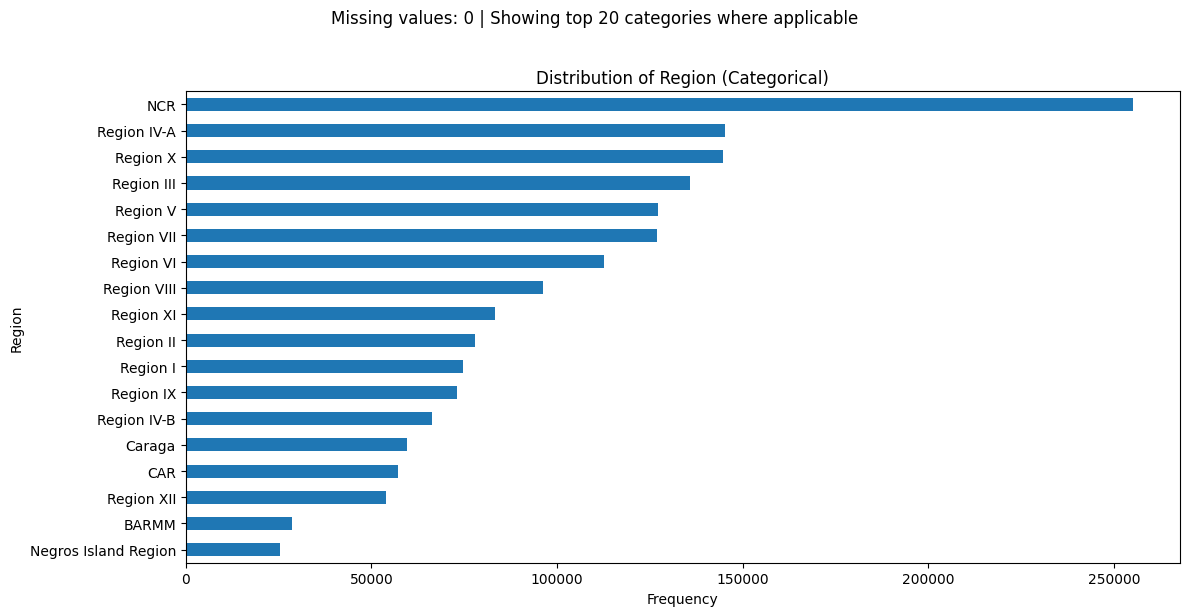

,Value,Count,Percentage (%)
0,NCR,254965,14.62
1,Region IV-A,145274,8.33
2,Region X,144659,8.3
3,Region III,135877,7.79
4,Region V,127139,7.29
5,Region VII,126861,7.28
6,Region VI,112723,6.47
7,Region VIII,96080,5.51
8,Region XI,83322,4.78
9,Region II,77838,4.46


In [15]:
plot_field = 'Region'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)



### Distribution: `Region of Awardee` — 18 unique values

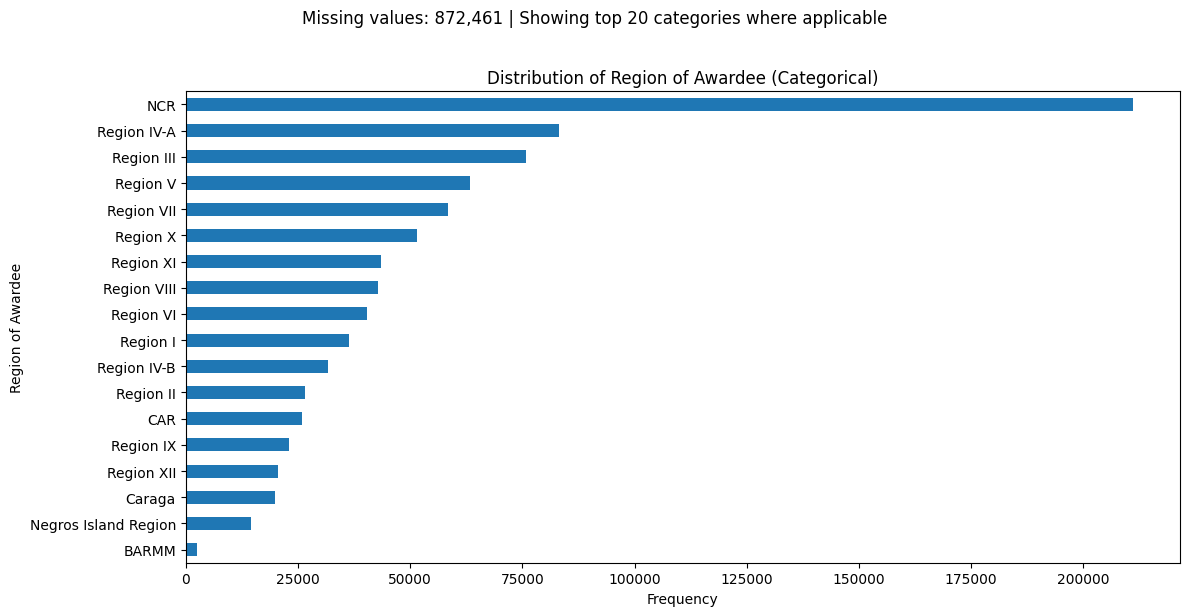

,Value,Count,Percentage (%)
0,(Missing),872461,50.04
1,NCR,210979,12.1
2,Region IV-A,83163,4.77
3,Region III,75899,4.35
4,Region V,63327,3.63
5,Region VII,58396,3.35
6,Region X,51464,2.95
7,Region XI,43467,2.49
8,Region VIII,42949,2.46
9,Region VI,40336,2.31


In [16]:
plot_field = 'Region of Awardee'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)



### Distribution: `Procurement Mode` — 19 unique values

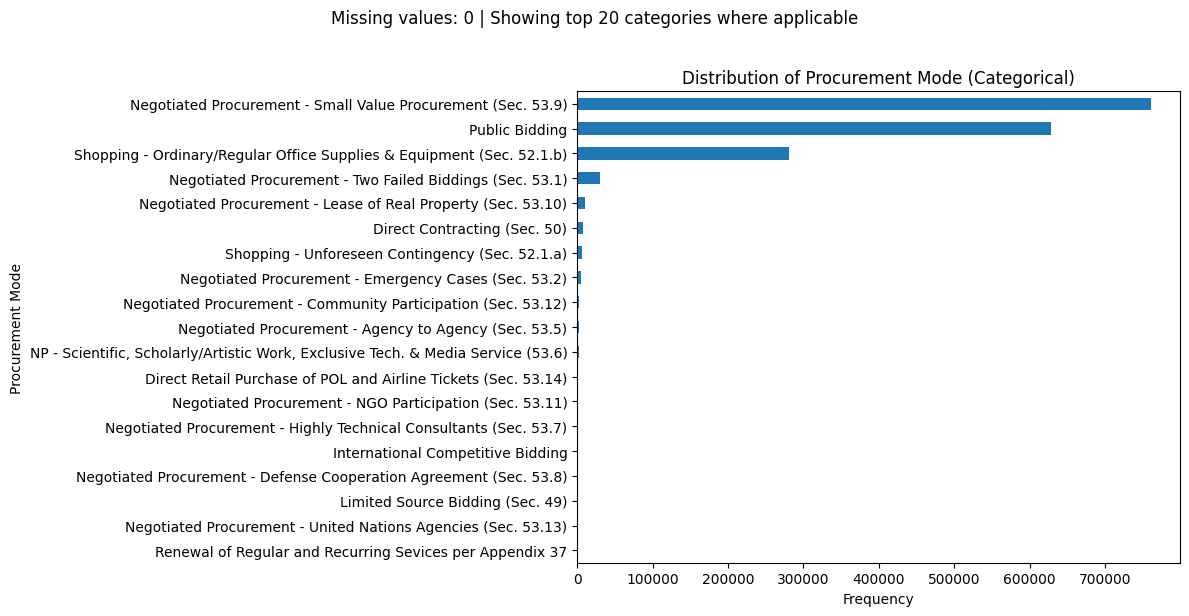

,Value,Count,Percentage (%)
0,Negotiated Procurement - Small Value Procurement (Sec. 53.9),761322,43.67
1,Public Bidding,628306,36.04
2,Shopping - Ordinary/Regular Office Supplies & Equipment (Sec. 52.1.b),281441,16.14
3,Negotiated Procurement - Two Failed Biddings (Sec. 53.1),29904,1.72
4,Negotiated Procurement - Lease of Real Property (Sec. 53.10),10832,0.62
5,Direct Contracting (Sec. 50),8312,0.48
6,Shopping - Unforeseen Contingency (Sec. 52.1.a),6647,0.38
7,Negotiated Procurement - Emergency Cases (Sec. 53.2),5681,0.33
8,Negotiated Procurement - Community Participation (Sec. 53.12),2253,0.13
9,Negotiated Procurement - Agency to Agency (Sec. 53.5),2163,0.12


In [17]:
plot_field = 'Procurement Mode'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)



### Distribution: `Country of Awardee` — 36 unique values

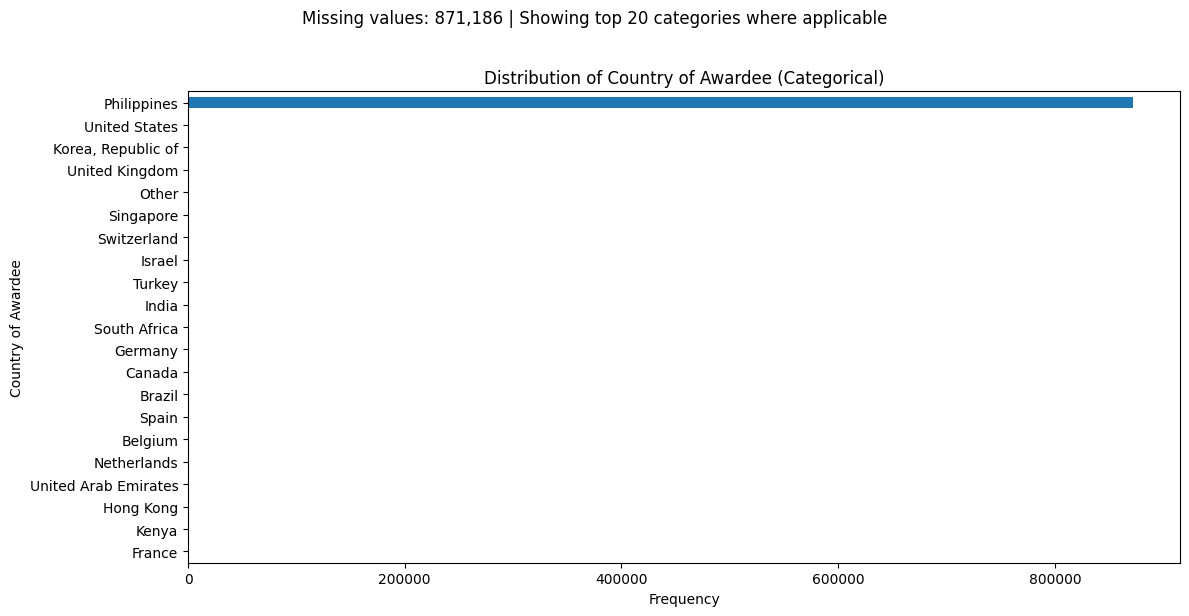

,Value,Count,Percentage (%)
0,Philippines,871932,50.01
1,(Missing),871186,49.97
2,United States,189,0.01
3,"Korea, Republic of",45,0.0
4,United Kingdom,28,0.0
5,Singapore,25,0.0
6,Switzerland,20,0.0
7,Israel,12,0.0
8,India,10,0.0
9,Turkey,10,0.0


In [18]:
plot_field = 'Country of Awardee'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)



### Distribution: `UOM` — 54 unique values

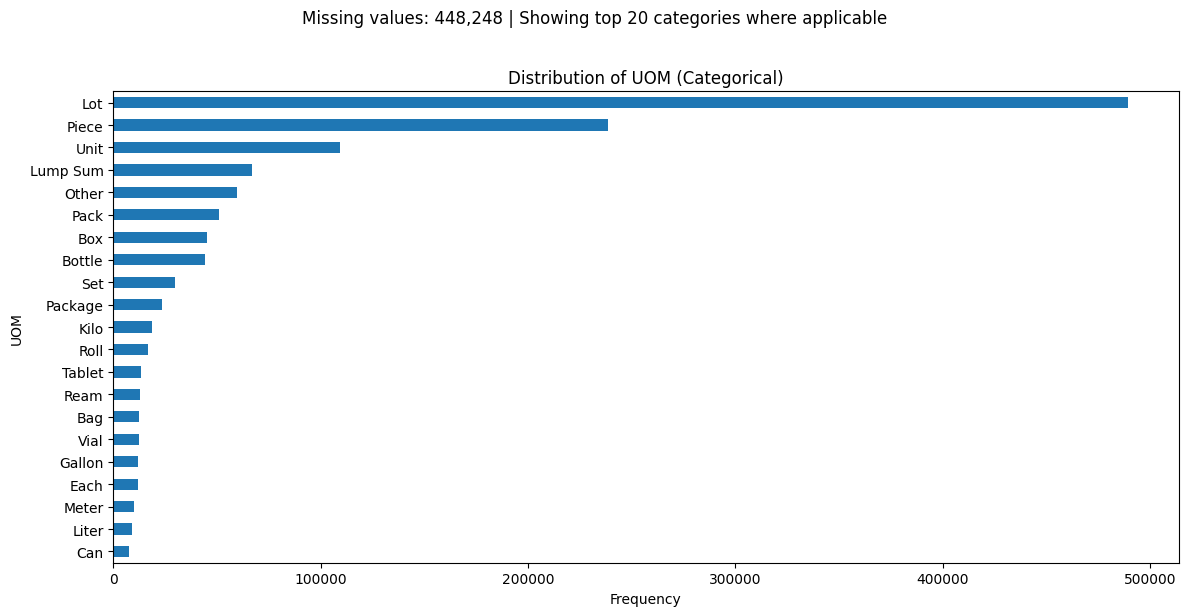

,Value,Count,Percentage (%)
0,Lot,489287,28.06
1,(Missing),448248,25.71
2,Piece,238806,13.7
3,Unit,109323,6.27
4,Lump Sum,66990,3.84
5,Pack,51216,2.94
6,Box,45409,2.6
7,Bottle,44303,2.54
8,Set,29623,1.7
9,Package,23612,1.35


In [19]:
plot_field = 'UOM'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)



### Distribution: `Province` — 83 unique values

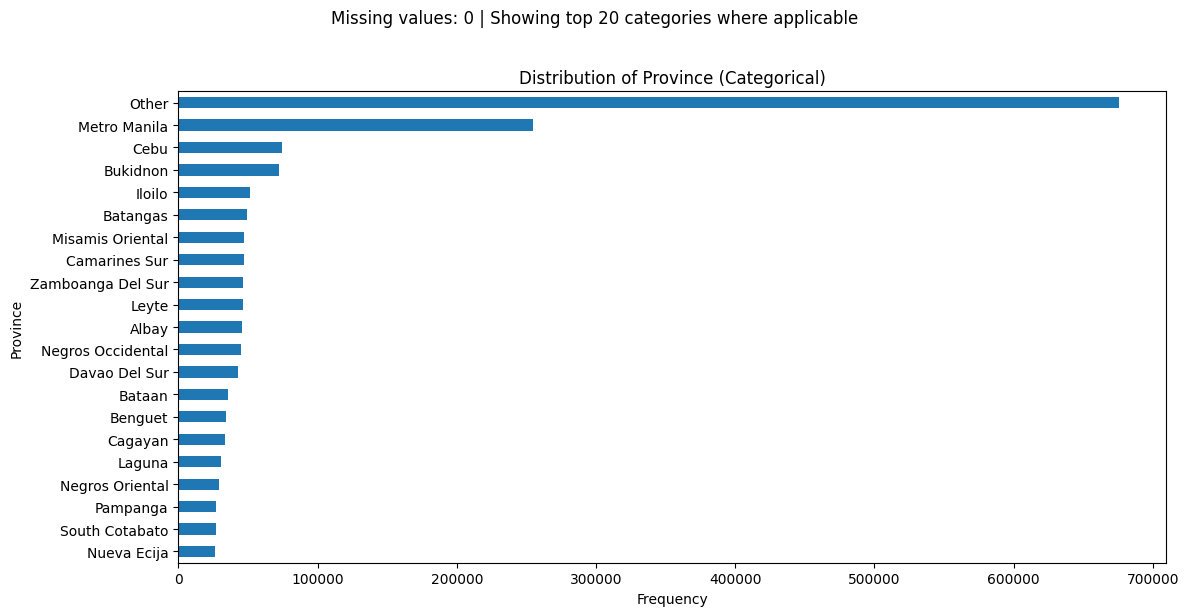

,Value,Count,Percentage (%)
0,Metro Manila,254906,14.62
1,Cebu,74452,4.27
2,Bukidnon,72171,4.14
3,Iloilo,51648,2.96
4,Batangas,49396,2.83
5,Misamis Oriental,47323,2.71
6,Camarines Sur,47291,2.71
7,Zamboanga Del Sur,46555,2.67
8,Leyte,46293,2.66
9,Albay,45723,2.62


In [20]:
plot_field = 'Province'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)



### Distribution: `Province of Awardee` — 83 unique values

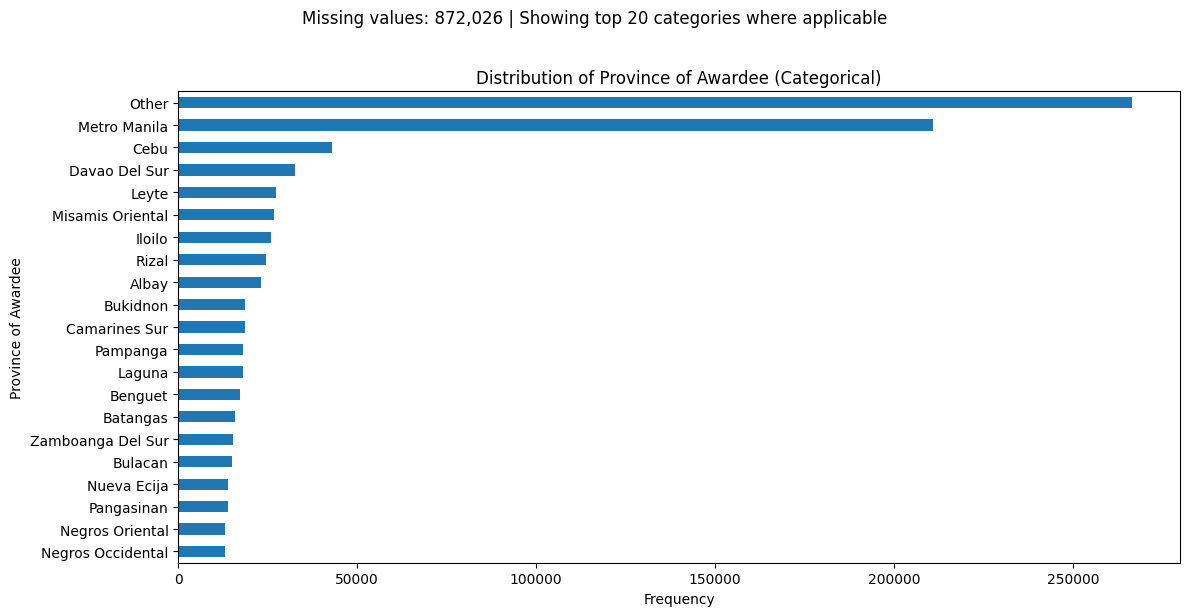

,Value,Count,Percentage (%)
0,(Missing),872026,50.01
1,Metro Manila,210977,12.1
2,Cebu,42934,2.46
3,Davao Del Sur,32674,1.87
4,Leyte,27249,1.56
5,Misamis Oriental,26795,1.54
6,Iloilo,25881,1.48
7,Rizal,24485,1.4
8,Albay,23142,1.33
9,Bukidnon,18742,1.07


In [21]:
plot_field = 'Province of Awardee'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)



### Distribution: `Area of Delivery` — 86 unique values

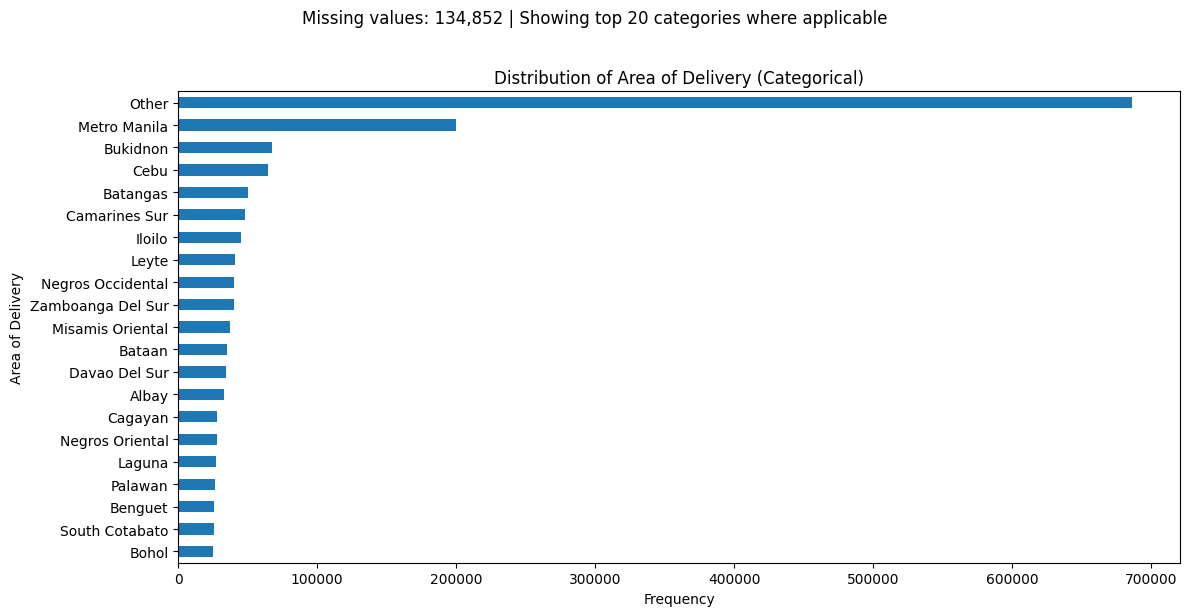

,Value,Count,Percentage (%)
0,Metro Manila,200168,11.48
1,(Missing),134852,7.73
2,Bukidnon,67430,3.87
3,Cebu,64209,3.68
4,Batangas,50210,2.88
5,Camarines Sur,47895,2.75
6,Iloilo,45244,2.59
7,Leyte,40875,2.34
8,Negros Occidental,40371,2.32
9,Zamboanga Del Sur,40173,2.3


In [22]:
plot_field = 'Area of Delivery'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)



## 7. Optional: export the combined dataset and field summary

Uncomment the lines below if you want to save the combined dataset and the field summary. Make sure you have enough disk space: the combined CSV may be large.

In [23]:
# OUTPUT_FOLDER = Path("data") / "processed"
# OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
#
# df.to_csv(OUTPUT_FOLDER / "philgeps_combined.csv", index=False)
# field_summary.to_csv(OUTPUT_FOLDER / "philgeps_field_summary.csv", index=False)
#
# print("Files exported to:", OUTPUT_FOLDER.resolve())